# Independent Model Validation

## The Economic Value of Smart EV Charging

**Market:** Germany–Luxembourg Day-Ahead Market

**Observation period:** 2025

**Data source:** Fraunhofer ISE Energy-Charts API
(Bundesnetzagentur SMARD)

---

## Research objective

This notebook independently evaluates the mathematical,
computational and economic consistency of the charging
simulation and sensitivity analyses.

The validation framework includes:

1. Structural integrity of exported datasets.
2. Independent mathematical optimisation.
3. Reconstruction of electricity expenditure.
4. Controlled tests of exceptional charging conditions.
5. Verification of temporal consistency.
6. Comparison of hourly and quarter-hourly optimisation.

The objective is to distinguish computationally verified
results from conclusions that remain conditional on
the underlying modelling assumptions.

No model parameters are adjusted to obtain agreement
with the desired economic conclusions.

## 1. Environment Setup and Data Loading

The original electricity price observations,
validated hourly prices, charging schedules and
sensitivity results are imported independently.

The notebook uses the exported research datasets
to verify the reproducibility of previous findings.

In [67]:
from pathlib import Path
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import linprog

# Identify project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Define directories
raw_dir = project_root / "data" / "raw"
processed_dir = project_root / "data" / "processed"
tables_dir = project_root / "outputs" / "tables"
figures_dir = project_root / "outputs" / "figures"

# Load hourly electricity prices
df_hourly = pd.read_csv(
    processed_dir / "DE_LU_day_ahead_2025_hourly.csv"
)

# Load interval-level charging schedules
simulation = pd.read_csv(
    processed_dir / "charging_simulation_2025.csv"
)

# Load session-level charging results
session_summary = pd.read_csv(
    processed_dir / "charging_session_results_2025.csv"
)

# Load annual economic results
annual_results = pd.read_csv(
    tables_dir / "annual_charging_results.csv",
    index_col="strategy"
)

# Load sensitivity results
duration_results = pd.read_csv(
    tables_dir / "flexibility_duration_results.csv",
    index_col="duration_hours"
)

timing_results = pd.read_csv(
    tables_dir / "flexibility_timing_results.csv",
    index_col="profile"
)

tariff_results = pd.read_csv(
    tables_dir / "tariff_sensitivity_results.csv",
    index_col="constant_charge_ct_kwh"
)

power_results = pd.read_csv(
    tables_dir / "charging_power_sensitivity_results.csv",
    index_col="charging_power_kw"
)

energy_results = pd.read_csv(
    tables_dir / "energy_demand_sensitivity_results.csv",
    index_col="annual_energy_kwh"
)

# Load original API response
with open(
    raw_dir / "DE_LU_day_ahead_2025.json",
    "r"
) as file:

    raw_data = json.load(file)

# Restore timezone-aware timestamps
for dataset in [df_hourly, simulation]:

    dataset["timestamp_utc"] = pd.to_datetime(
        dataset["timestamp_utc"],
        utc=True
    )

    dataset["timestamp_local"] = (
        dataset["timestamp_utc"]
        .dt.tz_convert("Europe/Berlin")
    )

print("All required research datasets loaded.")

print("\nHourly electricity prices:", len(df_hourly))
print("Charging schedule observations:", len(simulation))
print("Session-level observations:", len(session_summary))
print("Raw electricity prices:", len(raw_data["price"]))

All required research datasets loaded.

Hourly electricity prices: 8760
Charging schedule observations: 13104
Session-level observations: 1092
Raw electricity prices: 15483


## 2. Reference parameters and validation framework

In [68]:
# Reference model parameters
BATTERY_CAPACITY_KWH = 45.0
MAX_CHARGING_POWER_KW = 11.0
ANNUAL_HOME_GRID_ENERGY_KWH = 1584.0
CHARGING_EFFICIENCY = 0.95
TARGET_SOC = 0.60

CONSTANT_CHARGES_EUR_KWH = 0.20
FLAT_TARIFF_EUR_KWH = 0.30

DAYS_PER_YEAR = 365
N_SESSIONS = 364

DAILY_GRID_ENERGY_KWH = (
    ANNUAL_HOME_GRID_ENERGY_KWH / DAYS_PER_YEAR
)

ANNUALISATION_FACTOR = DAYS_PER_YEAR / N_SESSIONS

TOLERANCE = 1e-8

strategies = [
    "Immediate",
    "Fixed-time",
    "Dynamic"
]

# Store validation results
validation_records = []


def record_check(name, passed, details=""):

    validation_records.append({
        "validation_test": name,
        "passed": bool(passed),
        "details": details
    })

    status = "PASS" if passed else "FAIL"

    print(f"[{status}] {name}")

## 3. V1: Independent Data Integrity Audit

The exported datasets are examined for structural
consistency, temporal completeness, duplicate records
and invalid numerical observations.

The validation is performed independently of the
original data ingestion and simulation notebooks.

In [69]:
# Reconstruct expected hourly timestamp index
expected_index = pd.date_range(
    start="2025-01-01",
    end="2026-01-01",
    freq="h",
    inclusive="left",
    tz="Europe/Berlin"
).tz_convert("UTC")

actual_index = pd.DatetimeIndex(
    df_hourly["timestamp_utc"]
).sort_values()

record_check(
    "V1.1 Complete hourly dataset",
    actual_index.equals(expected_index),
    "Expected 8,760 hourly observations."
)

record_check(
    "V1.2 Unique electricity timestamps",
    df_hourly["timestamp_utc"].is_unique
)

record_check(
    "V1.3 Finite electricity prices",
    np.isfinite(df_hourly["price_eur_kwh"]).all()
)

record_check(
    "V1.4 Correct electricity price conversion",
    np.allclose(
        df_hourly["price_eur_kwh"],
        df_hourly["price_eur_mwh"] / 1000,
        atol=TOLERANCE,
        rtol=0
    )
)

record_check(
    "V1.5 Expected simulation dimensions",
    len(simulation) == 13104
)

record_check(
    "V1.6 Expected session-level dimensions",
    len(session_summary) == 1092
)

record_check(
    "V1.7 Unique charging schedule records",
    not simulation.duplicated(
        ["session_id", "strategy", "timestamp_utc"]
    ).any()
)

record_check(
    "V1.8 Unique strategy-session combinations",
    not session_summary.duplicated(
        ["session_id", "strategy"]
    ).any()
)

record_check(
    "V1.9 No missing simulation observations",
    not simulation.isna().any().any()
)

# Verify simulation prices against the market dataset
market_prices = df_hourly.set_index(
    "timestamp_utc"
)["price_eur_kwh"]

expected_prices = simulation[
    "timestamp_utc"
].map(market_prices)

record_check(
    "V1.10 Charging prices match market prices",
    np.allclose(
        simulation["price_eur_kwh"],
        expected_prices,
        atol=TOLERANCE,
        rtol=0
    )
)

assert all(
    check["passed"]
    for check in validation_records
)

print("\nAll independent data integrity checks passed.")

[PASS] V1.1 Complete hourly dataset
[PASS] V1.2 Unique electricity timestamps
[PASS] V1.3 Finite electricity prices
[PASS] V1.4 Correct electricity price conversion
[PASS] V1.5 Expected simulation dimensions
[PASS] V1.6 Expected session-level dimensions
[PASS] V1.7 Unique charging schedule records
[PASS] V1.8 Unique strategy-session combinations
[PASS] V1.9 No missing simulation observations
[PASS] V1.10 Charging prices match market prices

All independent data integrity checks passed.


## 4. V2: Independent Linear Programming Validation

The optimal charging expenditure is independently
calculated using scipy.optimize.linprog.

The linear programming formulation minimises
electricity purchasing costs subject to:

- A fixed session-level energy requirement.
- Non-negative charging quantities.
- Maximum charging power in each interval.

The independently calculated minimum expenditure
is compared against the price-ranking algorithm
implemented in Notebook 02.

Alternative optimal charging schedules may exist
when electricity prices are identical. Consequently,
validation focuses on objective values and
constraint satisfaction rather than requiring
identical charging schedules.

#### 4.1 Implement independent solver

In [70]:
def solve_lp(
    prices,
    energy_required,
    max_power,
    interval_hours=1.0
):
    """
    Independently solve the session-level charging
    optimisation problem using linear programming.
    """

    prices = np.asarray(prices, dtype=float)

    durations = np.broadcast_to(
        np.asarray(interval_hours, dtype=float),
        prices.shape
    )

    capacities = max_power * durations

    # Equality constraint: total electricity demand
    A_eq = np.ones((1, len(prices)))

    b_eq = np.array([energy_required])

    # Charging quantity bounds
    bounds = [
        (0.0, capacity)
        for capacity in capacities
    ]

    # Independent mathematical optimisation
    result = linprog(
        c=prices,
        A_eq=A_eq,
        b_eq=b_eq,
        bounds=bounds,
        method="highs"
    )

    return result

#### 4.2 Validate all 364 dynamic charging sessions

In [71]:
# Retrieve original dynamically optimised schedules
dynamic_schedules = simulation.loc[
    simulation["strategy"] == "Dynamic"
].copy()

lp_records = []

for session_id, session in dynamic_schedules.groupby(
    "session_id",
    sort=True
):

    session = session.sort_values("timestamp_utc")

    prices = session["price_eur_kwh"].to_numpy()

    # Solve independently
    solution = solve_lp(
        prices=prices,
        energy_required=DAILY_GRID_ENERGY_KWH,
        max_power=MAX_CHARGING_POWER_KW,
        interval_hours=session[
            "interval_hours"
        ].to_numpy()
    )

    if not solution.success:

        raise RuntimeError(
            f"LP optimisation failed for {session_id}: "
            f"{solution.message}"
        )

    # Original model cost
    original_cost = session["spot_cost_eur"].sum()

    # Independent optimal cost
    lp_cost = solution.fun

    # Verify independent energy allocation
    assert np.isclose(
        solution.x.sum(),
        DAILY_GRID_ENERGY_KWH
    )

    assert (solution.x >= -TOLERANCE).all()

    assert (
        solution.x
        <= MAX_CHARGING_POWER_KW
        * session["interval_hours"].to_numpy()
        + TOLERANCE
    ).all()

    lp_records.append({
        "session_id": session_id,
        "original_cost_eur": original_cost,
        "lp_cost_eur": lp_cost,
        "absolute_difference_eur":
            abs(original_cost - lp_cost),
        "solver_success": solution.success
    })

lp_validation = pd.DataFrame(lp_records)

# Construct validation summary
lp_summary = pd.Series({
    "Sessions independently optimised":
        len(lp_validation),

    "Successful LP solutions":
        lp_validation["solver_success"].sum(),

    "Matching optimal costs":
        (
            lp_validation["absolute_difference_eur"]
            <= TOLERANCE
        ).sum(),

    "Maximum absolute difference (EUR)":
        lp_validation["absolute_difference_eur"].max(),

    "Total absolute difference (EUR)":
        lp_validation["absolute_difference_eur"].sum(),

    "Annualised LP wholesale cost (EUR)":
        lp_validation["lp_cost_eur"].sum()
        * ANNUALISATION_FACTOR
}, name="Value")

display(lp_summary.to_frame())

record_check(
    "V2.1 All reference sessions independently solved",
    len(lp_validation) == N_SESSIONS
    and lp_validation["solver_success"].all()
)

record_check(
    "V2.2 Original model matches LP optimum",
    (
        lp_validation["absolute_difference_eur"]
        <= TOLERANCE
    ).all()
)

assert (
    lp_validation["absolute_difference_eur"]
    <= TOLERANCE
).all()

print("\nIndependent optimisation validation completed.")

,Value
Sessions independently optimised,364.000000
Successful LP solutions,364.000000
Matching optimal costs,364.000000
Maximum absolute difference (EUR),0.000000
Total absolute difference (EUR),0.000000
Annualised LP wholesale cost (EUR),121.134648


[PASS] V2.1 All reference sessions independently solved
[PASS] V2.2 Original model matches LP optimum

Independent optimisation validation completed.


## 5. V3: Independent Economic Reconstruction

Annualised electricity expenditure is reconstructed
directly from interval-level charging quantities
and historical electricity prices.

The calculation does not rely on the previously
exported electricity cost columns.

The reconstructed results are compared against
the annual economic results from Notebook 02.

#### 5.1 Reconstruct annual expenditure

In [72]:
economic_audit = simulation.copy()

# Reconstruct market prices directly from source
economic_audit["market_price"] = (
    economic_audit["timestamp_utc"]
    .map(market_prices)
)

# Recalculate interval-level expenditure
economic_audit["reconstructed_spot_cost"] = (
    economic_audit["charging_kwh"]
    * economic_audit["market_price"]
)

economic_audit["reconstructed_retail_cost"] = (
    economic_audit["charging_kwh"]
    * (
        economic_audit["market_price"]
        + CONSTANT_CHARGES_EUR_KWH
    )
)

# Compare original and reconstructed costs
record_check(
    "V3.1 Correct interval-level wholesale costs",
    np.allclose(
        economic_audit["spot_cost_eur"],
        economic_audit["reconstructed_spot_cost"],
        atol=TOLERANCE,
        rtol=0
    )
)

record_check(
    "V3.2 Correct interval-level retail costs",
    np.allclose(
        economic_audit["retail_cost_eur"],
        economic_audit["reconstructed_retail_cost"],
        atol=TOLERANCE,
        rtol=0
    )
)

# Reconstruct annual totals
reconstructed_annual = (
    economic_audit.groupby("strategy")
    .agg(
        annual_energy_kwh=("charging_kwh", "sum"),
        annual_spot_cost_eur=(
            "reconstructed_spot_cost", "sum"
        ),
        annual_retail_cost_eur=(
            "reconstructed_retail_cost", "sum"
        )
    )
    .reindex(strategies)
    * ANNUALISATION_FACTOR
)

# Compare annual totals
economic_validation = []

for strategy in strategies:

    for indicator in reconstructed_annual.columns:

        original = annual_results.loc[
            strategy, indicator
        ]

        reconstructed = reconstructed_annual.loc[
            strategy, indicator
        ]

        economic_validation.append({
            "strategy": strategy,
            "indicator": indicator,
            "original": original,
            "reconstructed": reconstructed,
            "absolute_difference":
                abs(original - reconstructed)
        })

economic_validation = pd.DataFrame(
    economic_validation
)

display(economic_validation.round(8))

record_check(
    "V3.3 Annual economic results reproduced",
    (
        economic_validation["absolute_difference"]
        <= TOLERANCE
    ).all()
)

[PASS] V3.1 Correct interval-level wholesale costs
[PASS] V3.2 Correct interval-level retail costs


,strategy,indicator,original,reconstructed,absolute_difference
0,Immediate,annual_energy_kwh,1584.000000,1584.000000,0.0
1,Immediate,annual_spot_cost_eur,196.814111,196.814111,0.0
2,Immediate,annual_retail_cost_eur,513.614111,513.614111,0.0
3,Fixed-time,annual_energy_kwh,1584.000000,1584.000000,0.0
4,Fixed-time,annual_spot_cost_eur,141.124696,141.124696,0.0
5,Fixed-time,annual_retail_cost_eur,457.924696,457.924696,0.0
6,Dynamic,annual_energy_kwh,1584.000000,1584.000000,0.0
7,Dynamic,annual_spot_cost_eur,121.134648,121.134648,0.0
8,Dynamic,annual_retail_cost_eur,437.934648,437.934648,0.0


[PASS] V3.3 Annual economic results reproduced


#### 5.2 Reconstruct principal savings indicators

In [73]:
# Retrieve independently reconstructed expenditure

immediate_cost = reconstructed_annual.loc[
    "Immediate", "annual_retail_cost_eur"
]

fixed_cost = reconstructed_annual.loc[
    "Fixed-time", "annual_retail_cost_eur"
]

dynamic_cost = reconstructed_annual.loc[
    "Dynamic", "annual_retail_cost_eur"
]

# Independently reconstruct economic indicators

reconstructed_savings = pd.Series({
    "Fixed-time annual savings (EUR)":
        immediate_cost - fixed_cost,

    "Dynamic annual savings (EUR)":
        immediate_cost - dynamic_cost,

    "Dynamic retail savings (%)":
        (immediate_cost - dynamic_cost)
        / immediate_cost * 100,

    "Incremental dynamic value (EUR)":
        fixed_cost - dynamic_cost,

    "Fixed-time share of dynamic savings (%)":
        (immediate_cost - fixed_cost)
        / (immediate_cost - dynamic_cost) * 100

}, name="Value")

display(reconstructed_savings.to_frame().round(4))

# Independently validate economic indicators

record_check(
    "V3.4 Dynamic savings correctly calculated",
    np.isclose(
        immediate_cost - dynamic_cost,
        annual_results.loc[
            "Dynamic", "retail_savings_eur"
        ],
        atol=TOLERANCE,
        rtol=0
    )
)

record_check(
    "V3.5 Fixed-time savings correctly calculated",
    np.isclose(
        immediate_cost - fixed_cost,
        annual_results.loc[
            "Fixed-time", "retail_savings_eur"
        ],
        atol=TOLERANCE,
        rtol=0
    )
)

record_check(
    "V3.6 Relative dynamic savings correctly calculated",
    np.isclose(
        (immediate_cost - dynamic_cost)
        / immediate_cost * 100,
        annual_results.loc[
            "Dynamic", "retail_savings_pct"
        ],
        atol=TOLERANCE,
        rtol=0
    )
)

,Value
Fixed-time annual savings (EUR),55.6894
Dynamic annual savings (EUR),75.6795
Dynamic retail savings (%),14.7347
Incremental dynamic value (EUR),19.9900
Fixed-time share of dynamic savings (%),73.5859


[PASS] V3.4 Dynamic savings correctly calculated
[PASS] V3.5 Fixed-time savings correctly calculated
[PASS] V3.6 Relative dynamic savings correctly calculated


## 6. V4: Exceptional charging conditions

#### 6.1 Reimplement the price-ranking algorithm for testing

In [74]:
def greedy_solution(
    prices,
    energy_required,
    max_power,
    interval_hours=1.0
):
    """
    Price-ranked charging allocation used to
    compare against the independent LP solver.
    """

    prices = np.asarray(prices, dtype=float)

    durations = np.broadcast_to(
        np.asarray(interval_hours, dtype=float),
        prices.shape
    )

    capacity = max_power * durations

    if energy_required < 0:
        raise ValueError("Negative energy requirement.")

    if max_power <= 0:
        raise ValueError("Invalid charging power.")

    if capacity.sum() + TOLERANCE < energy_required:

        raise ValueError(
            "Infeasible charging requirement."
        )

    allocation = np.zeros(len(prices))

    remaining = float(energy_required)

    for index in np.argsort(prices, kind="stable"):

        if remaining <= TOLERANCE:
            break

        quantity = min(
            remaining,
            capacity[index]
        )

        allocation[index] = quantity

        remaining -= quantity

    return allocation

#### 6.2 Test controlled scenarios

In [75]:
test_cases = [
    {
        "name": "Constant prices",
        "prices": [0.10, 0.10, 0.10],
        "energy": 5.0,
        "expected_cost": 0.50
    },
    {
        "name": "Negative prices",
        "prices": [-0.10, 0.05, 0.20],
        "energy": 5.0,
        "expected_cost": -0.20
    },
    {
        "name": "Multi-interval charging",
        "prices": [0.20, 0.05, 0.10],
        "energy": 5.0,
        "expected_cost": 0.35
    },
    {
        "name": "Tied minimum prices",
        "prices": [0.05, 0.05, 0.20],
        "energy": 5.0,
        "expected_cost": 0.25
    },
    {
        "name": "Zero energy requirement",
        "prices": [-0.20, 0.10],
        "energy": 0.0,
        "expected_cost": 0.00
    }
]

edge_records = []

for case in test_cases:

    prices = np.array(case["prices"])

    # Price-ranked solution
    allocation = greedy_solution(
        prices=prices,
        energy_required=case["energy"],
        max_power=3.0
    )

    greedy_cost = np.dot(
        allocation,
        prices
    )

    # Independent LP solution
    solution = solve_lp(
        prices=prices,
        energy_required=case["energy"],
        max_power=3.0
    )

    passed = (
        solution.success
        and np.isclose(
            greedy_cost,
            case["expected_cost"]
        )
        and np.isclose(
            solution.fun,
            case["expected_cost"]
        )
        and np.isclose(
            allocation.sum(),
            case["energy"]
        )
        and (allocation >= -TOLERANCE).all()
        and (allocation <= 3 + TOLERANCE).all()
    )

    edge_records.append({
        "test": case["name"],
        "expected_cost_eur": case["expected_cost"],
        "greedy_cost_eur": greedy_cost,
        "lp_cost_eur": solution.fun,
        "energy_allocated_kwh": allocation.sum(),
        "passed": passed
    })

edge_case_results = pd.DataFrame(edge_records)

display(edge_case_results.round(4))

record_check(
    "V4.1 Controlled mathematical examples",
    edge_case_results["passed"].all()
)

,test,expected_cost_eur,greedy_cost_eur,lp_cost_eur,energy_allocated_kwh,passed
0,Constant prices,0.50,0.50,0.50,5.0,True
1,Negative prices,-0.20,-0.20,-0.20,5.0,True
2,Multi-interval charging,0.35,0.35,0.35,5.0,True
3,Tied minimum prices,0.25,0.25,0.25,5.0,True
4,Zero energy requirement,0.00,0.00,0.00,0.0,True


[PASS] V4.1 Controlled mathematical examples


#### 6.3 Explicit infeasibility test

In [76]:
# Infeasible charging scenario
infeasible_prices = [0.10, 0.20]

greedy_rejected = False

try:

    greedy_solution(
        prices=infeasible_prices,
        energy_required=10.0,
        max_power=3.0
    )

except ValueError:

    greedy_rejected = True

# Independent LP infeasibility check
infeasible_lp = solve_lp(
    prices=infeasible_prices,
    energy_required=10.0,
    max_power=3.0
)

record_check(
    "V4.2 Greedy algorithm rejects infeasible demand",
    greedy_rejected
)

record_check(
    "V4.3 LP solver identifies infeasible demand",
    not infeasible_lp.success
    and infeasible_lp.status == 2
)

print("\nExceptional charging condition tests completed.")

[PASS] V4.2 Greedy algorithm rejects infeasible demand
[PASS] V4.3 LP solver identifies infeasible demand

Exceptional charging condition tests completed.


## 7. V5: Temporal consistency and physical constraints

#### 7.1 Indipendent reconstruction of charging sessions

In [77]:
expected_sessions = []

for date in pd.date_range(
    "2025-01-01",
    "2025-12-30",
    freq="D"
):

    arrival = (
        date + pd.Timedelta(hours=18)
    ).tz_localize("Europe/Berlin")

    departure = (
        date
        + pd.Timedelta(days=1)
        + pd.Timedelta(hours=6)
    ).tz_localize("Europe/Berlin")

    intervals = pd.date_range(
        start=arrival,
        end=departure,
        freq="h",
        inclusive="left"
    ).tz_convert("UTC")

    expected_sessions.append(
        pd.DataFrame({
            "session_id": date.strftime("%Y-%m-%d"),
            "timestamp_utc": intervals
        })
    )

expected_sessions = pd.concat(
    expected_sessions,
    ignore_index=True
)

# Compare each strategy's feasible intervals
for strategy in strategies:

    actual = (
        simulation.loc[
            simulation["strategy"] == strategy,
            ["session_id", "timestamp_utc"]
        ]
        .sort_values(["session_id", "timestamp_utc"])
        .reset_index(drop=True)
    )

    expected = (
        expected_sessions
        .sort_values(["session_id", "timestamp_utc"])
        .reset_index(drop=True)
    )

    record_check(
        f"V5.1 Correct session windows — {strategy}",
        actual.equals(expected)
    )

[PASS] V5.1 Correct session windows — Immediate
[PASS] V5.1 Correct session windows — Fixed-time
[PASS] V5.1 Correct session windows — Dynamic


#### 7.2 — Verify daylight-saving transitions

In [78]:
session_lengths = (
    expected_sessions
    .groupby("session_id")
    .size()
)

dst_sessions = session_lengths.loc[
    session_lengths != 12
]

display(
    dst_sessions.to_frame(
        name="available_hours"
    )
)

record_check(
    "V5.2 Spring daylight-saving transition",
    session_lengths.loc["2025-03-29"] == 11
)

record_check(
    "V5.3 Autumn daylight-saving transition",
    session_lengths.loc["2025-10-25"] == 13
)

record_check(
    "V5.4 Correct number of complete sessions",
    len(session_lengths) == 364
)

record_check(
    "V5.5 Correct total available charging hours",
    session_lengths.sum() == 4368
)

,available_hours
session_id,
2025-03-29,11
2025-10-25,13


[PASS] V5.2 Spring daylight-saving transition
[PASS] V5.3 Autumn daylight-saving transition
[PASS] V5.4 Correct number of complete sessions
[PASS] V5.5 Correct total available charging hours


#### 7.3 Reconstruct physical battery constraints

In [79]:
physical_audit = simulation.sort_values([
    "session_id",
    "strategy",
    "timestamp_utc"
]).copy()

# Calculate implied battery energy at arrival
arrival_energy = (
    BATTERY_CAPACITY_KWH * TARGET_SOC
    - DAILY_GRID_ENERGY_KWH * CHARGING_EFFICIENCY
)

# Independently reconstruct battery energy
physical_audit["reconstructed_battery_kwh"] = (
    arrival_energy
    + physical_audit.groupby(
        ["session_id", "strategy"]
    )["charging_kwh"].cumsum()
    * CHARGING_EFFICIENCY
)

physical_audit["reconstructed_soc_pct"] = (
    physical_audit["reconstructed_battery_kwh"]
    / BATTERY_CAPACITY_KWH
    * 100
)

record_check(
    "V5.6 Battery state of charge reproduced",
    np.allclose(
        physical_audit["soc_pct"],
        physical_audit["reconstructed_soc_pct"],
        atol=TOLERANCE,
        rtol=0
    )
)

record_check(
    "V5.7 Maximum charging power respected",
    (
        physical_audit["charging_kwh"]
        <= MAX_CHARGING_POWER_KW
        * physical_audit["interval_hours"]
        + TOLERANCE
    ).all()
)

record_check(
    "V5.8 Non-negative charging quantities",
    (
        physical_audit["charging_kwh"] >= -TOLERANCE
    ).all()
)

record_check(
    "V5.9 Battery capacity respected",
    physical_audit[
        "reconstructed_battery_kwh"
    ].between(
        -TOLERANCE,
        BATTERY_CAPACITY_KWH + TOLERANCE
    ).all()
)

final_soc = (
    physical_audit.groupby(
        ["session_id", "strategy"]
    )["reconstructed_soc_pct"].last()
)

record_check(
    "V5.10 Identical departure SOC",
    np.allclose(
        final_soc,
        TARGET_SOC * 100,
        atol=TOLERANCE,
        rtol=0
    )
)

session_energy = (
    physical_audit.groupby(
        ["session_id", "strategy"]
    )["charging_kwh"].sum()
)

record_check(
    "V5.11 Identical session energy requirements",
    np.allclose(
        session_energy,
        DAILY_GRID_ENERGY_KWH,
        atol=TOLERANCE,
        rtol=0
    )
)

[PASS] V5.6 Battery state of charge reproduced
[PASS] V5.7 Maximum charging power respected
[PASS] V5.8 Non-negative charging quantities
[PASS] V5.9 Battery capacity respected
[PASS] V5.10 Identical departure SOC
[PASS] V5.11 Identical session energy requirements


## 8. V6: Temporal Resolution Robustness

The impact of hourly electricity price aggregation
is investigated by comparing hourly and native
quarter-hourly charging optimisation.

The experiment uses matched complete overnight
sessions between 1 October and 30 December 2025.

Electricity demand, maximum charging power,
availability windows and tariff assumptions
remain unchanged.

Only temporal resolution varies.

The results are reported for the observed
fourth-quarter sessions without annualisation.

In [80]:
# Recover original API observations
df_native = pd.DataFrame({
    "timestamp_utc": pd.to_datetime(
        raw_data["unix_seconds"],
        unit="s",
        utc=True
    ),
    "price_eur_mwh": raw_data["price"]
})

df_native["timestamp_local"] = (
    df_native["timestamp_utc"]
    .dt.tz_convert("Europe/Berlin")
)

# Restrict to native quarter-hourly market period
df_quarterly = df_native.loc[
    (df_native["timestamp_local"]
     >= pd.Timestamp(
         "2025-10-01",
         tz="Europe/Berlin"
     ))
    &
    (df_native["timestamp_local"]
     < pd.Timestamp(
         "2026-01-01",
         tz="Europe/Berlin"
     ))
].copy()

df_quarterly["price_eur_kwh"] = (
    df_quarterly["price_eur_mwh"] / 1000
)

df_quarterly = (
    df_quarterly
    .sort_values("timestamp_utc")
    .reset_index(drop=True)
)

# Independently verify quarter-hourly completeness
expected_quarterly_index = pd.date_range(
    start="2025-10-01",
    end="2026-01-01",
    freq="15min",
    inclusive="left",
    tz="Europe/Berlin"
).tz_convert("UTC")

record_check(
    "V6.1 Complete quarter-hourly dataset",
    pd.DatetimeIndex(
        df_quarterly["timestamp_utc"]
    ).equals(expected_quarterly_index)
)

record_check(
    "V6.2 Finite quarter-hourly prices",
    np.isfinite(
        df_quarterly["price_eur_kwh"]
    ).all()
)

print("\nQuarter-hourly observations:", len(df_quarterly))

display(df_quarterly.head())

[PASS] V6.1 Complete quarter-hourly dataset
[PASS] V6.2 Finite quarter-hourly prices

Quarter-hourly observations: 8836


,timestamp_utc,price_eur_mwh,timestamp_local,price_eur_kwh
0,2025-09-30 22:00:00+00:00,102.60,2025-10-01 00:00:00+02:00,0.10260
1,2025-09-30 22:15:00+00:00,92.24,2025-10-01 00:15:00+02:00,0.09224
2,2025-09-30 22:30:00+00:00,86.03,2025-10-01 00:30:00+02:00,0.08603
3,2025-09-30 22:45:00+00:00,85.39,2025-10-01 00:45:00+02:00,0.08539
4,2025-09-30 23:00:00+00:00,89.99,2025-10-01 01:00:00+02:00,0.08999


#### 8.1 Verify hourly aggregation indipendently

In [81]:
# Independently aggregate native prices
quarterly_aggregation = (
    df_quarterly
    .set_index("timestamp_utc")
    ["price_eur_kwh"]
    .resample("h")
    .mean()
)

# Retrieve corresponding existing hourly prices
existing_hourly = (
    market_prices.reindex(
        quarterly_aggregation.index
    )
)

aggregation_difference = (
    quarterly_aggregation - existing_hourly
).abs()

record_check(
    "V6.3 Hourly aggregation independently reproduced",
    np.allclose(
        quarterly_aggregation,
        existing_hourly,
        atol=TOLERANCE,
        rtol=0
    )
)

print(
    "Maximum hourly aggregation difference:",
    aggregation_difference.max()
)


[PASS] V6.3 Hourly aggregation independently reproduced
Maximum hourly aggregation difference: 5.551115123125783e-17


#### 8.2 Compare charging strategies at both resolutions

In [82]:
quarterly_prices = df_quarterly.set_index(
    "timestamp_utc"
)["price_eur_kwh"]

q4_dates = pd.date_range(
    start="2025-10-01",
    end="2025-12-30",
    freq="D"
)

resolution_records = []

for date in q4_dates:

    arrival = (
        date + pd.Timedelta(hours=18)
    ).tz_localize("Europe/Berlin")

    departure = (
        date
        + pd.Timedelta(days=1)
        + pd.Timedelta(hours=6)
    ).tz_localize("Europe/Berlin")

    for resolution, frequency, dt, lookup in [
        ("Hourly", "h", 1.0, market_prices),
        ("Quarter-hourly", "15min", 0.25, quarterly_prices)
    ]:

        timestamps = pd.date_range(
            start=arrival,
            end=departure,
            freq=frequency,
            inclusive="left"
        ).tz_convert("UTC")

        prices = lookup.reindex(
            timestamps
        ).to_numpy()

        assert np.isfinite(prices).all()

        # Capacity per charging interval
        capacity = MAX_CHARGING_POWER_KW * dt

        # Immediate and fixed-time charging
        for strategy in ["Immediate", "Fixed-time"]:

            allocation = np.zeros(len(prices))

            remaining = DAILY_GRID_ENERGY_KWH

            if strategy == "Immediate":

                eligible_indices = np.arange(
                    len(prices)
                )

            else:

                midnight = (
                    date + pd.Timedelta(days=1)
                ).tz_localize(
                    "Europe/Berlin"
                ).tz_convert("UTC")

                eligible_indices = np.flatnonzero(
                    timestamps >= midnight
                )

            for index in eligible_indices:

                if remaining <= TOLERANCE:
                    break

                quantity = min(
                    remaining,
                    capacity
                )

                allocation[index] = quantity

                remaining -= quantity

            assert remaining <= TOLERANCE

            assert np.isclose(
                allocation.sum(),
                DAILY_GRID_ENERGY_KWH
            )

            assert (
                allocation <= capacity + TOLERANCE
            ).all()

            spot_cost = np.dot(
                allocation,
                prices
            )

            resolution_records.append({
                "session_id": date.strftime("%Y-%m-%d"),
                "resolution": resolution,
                "strategy": strategy,
                "energy_kwh": allocation.sum(),
                "spot_cost_eur": spot_cost,
                "retail_cost_eur":
                    spot_cost
                    + CONSTANT_CHARGES_EUR_KWH
                    * allocation.sum()
            })

        # Dynamic charging using independent LP solver
        solution = solve_lp(
            prices=prices,
            energy_required=DAILY_GRID_ENERGY_KWH,
            max_power=MAX_CHARGING_POWER_KW,
            interval_hours=dt
        )

        assert solution.success

        assert np.isclose(
            solution.x.sum(),
            DAILY_GRID_ENERGY_KWH
        )

        assert (
            solution.x <= capacity + TOLERANCE
        ).all()

        spot_cost = solution.fun

        resolution_records.append({
            "session_id": date.strftime("%Y-%m-%d"),
            "resolution": resolution,
            "strategy": "Dynamic",
            "energy_kwh": solution.x.sum(),
            "spot_cost_eur": spot_cost,
            "retail_cost_eur":
                spot_cost
                + CONSTANT_CHARGES_EUR_KWH
                * solution.x.sum()
        })

resolution_session_results = pd.DataFrame(
    resolution_records
)

print("Matched Q4 charging sessions:", len(q4_dates))

print(
    "Strategy-resolution-session combinations:",
    len(resolution_session_results)
)

record_check(
    "V6.4 Expected matched-session dimensions",
    len(resolution_session_results) == 91 * 3 * 2
)

record_check(
    "V6.5 Identical energy across resolutions",
    np.allclose(
        resolution_session_results["energy_kwh"],
        DAILY_GRID_ENERGY_KWH
    )
)

Matched Q4 charging sessions: 91
Strategy-resolution-session combinations: 546
[PASS] V6.4 Expected matched-session dimensions
[PASS] V6.5 Identical energy across resolutions


#### 8.3 Validate the resolution comparison

In [83]:
# Compare optimised expenditure per session
dynamic_resolution_costs = (
    resolution_session_results.loc[
        resolution_session_results["strategy"]
        == "Dynamic"
    ]
    .pivot(
        index="session_id",
        columns="resolution",
        values="retail_cost_eur"
    )
)

# Finer resolution cannot increase the true
# optimum under the equivalent feasible model
record_check(
    "V6.6 Quarter-hourly optimum no more expensive",
    (
        dynamic_resolution_costs["Quarter-hourly"]
        <= dynamic_resolution_costs["Hourly"]
        + TOLERANCE
    ).all()
)

# Compare hourly results against Notebook 02
original_q4 = session_summary.loc[
    session_summary["session_id"].isin(
        q4_dates.strftime("%Y-%m-%d")
    ),
    ["session_id", "strategy", "retail_cost_eur"]
]

independent_hourly_q4 = (
    resolution_session_results.loc[
        resolution_session_results["resolution"]
        == "Hourly",
        ["session_id", "strategy", "retail_cost_eur"]
    ]
)

q4_comparison = original_q4.merge(
    independent_hourly_q4,
    on=["session_id", "strategy"],
    how="outer",
    validate="one_to_one",
    suffixes=("_original", "_independent"),
    indicator=True
)

record_check(
    "V6.7 Independent hourly Q4 costs reproduced",
    len(q4_comparison) == 91 * 3
    and q4_comparison["_merge"].eq("both").all()
    and np.allclose(
        q4_comparison["retail_cost_eur_original"],
        q4_comparison["retail_cost_eur_independent"],
        atol=TOLERANCE,
        rtol=0
    )
)

[PASS] V6.6 Quarter-hourly optimum no more expensive
[PASS] V6.7 Independent hourly Q4 costs reproduced


#### 8.4 Calculate economic effects of finer resolution

In [84]:
resolution_summary = (
    resolution_session_results
    .groupby(["resolution", "strategy"])
    .agg(
        sessions=("session_id", "count"),
        energy_kwh=("energy_kwh", "sum"),
        spot_cost_eur=("spot_cost_eur", "sum"),
        retail_cost_eur=("retail_cost_eur", "sum")
    )
    .reset_index()
)

# Compare total Q4 expenditure
resolution_costs = (
    resolution_summary.pivot(
        index="strategy",
        columns="resolution",
        values="retail_cost_eur"
    )
    .reindex(strategies)
)

resolution_costs["Cost reduction (EUR)"] = (
    resolution_costs["Hourly"]
    - resolution_costs["Quarter-hourly"]
)

resolution_costs["Cost reduction (%)"] = (
    resolution_costs["Cost reduction (EUR)"]
    / resolution_costs["Hourly"]
    * 100
)

# Compare strategy-level savings
resolution_savings = pd.DataFrame({
    resolution: {
        "Fixed-time savings":
            resolution_costs.loc[
                "Immediate", resolution
            ]
            - resolution_costs.loc[
                "Fixed-time", resolution
            ],

        "Dynamic savings":
            resolution_costs.loc[
                "Immediate", resolution
            ]
            - resolution_costs.loc[
                "Dynamic", resolution
            ],

        "Incremental dynamic value":
            resolution_costs.loc[
                "Fixed-time", resolution
            ]
            - resolution_costs.loc[
                "Dynamic", resolution
            ]
    }

    for resolution in ["Hourly", "Quarter-hourly"]
})

resolution_savings["Change in savings (EUR)"] = (
    resolution_savings["Quarter-hourly"]
    - resolution_savings["Hourly"]
)

print("Q4 expenditure comparison (EUR)")
display(resolution_costs.round(4))

print("Q4 savings comparison (EUR)")
display(resolution_savings.round(4))

Q4 expenditure comparison (EUR)


resolution,Hourly,Quarter-hourly,Cost reduction (EUR),Cost reduction (%)
strategy,,,,
Immediate,130.3041,128.8977,1.4064,1.0793
Fixed-time,108.7812,110.6756,-1.8944,-1.7415
Dynamic,104.9169,103.6475,1.2694,1.2099


Q4 savings comparison (EUR)


,Hourly,Quarter-hourly,Change in savings (EUR)
Fixed-time savings,21.5230,18.2221,-3.3008
Dynamic savings,25.3872,25.2503,-0.1370
Incremental dynamic value,3.8643,7.0281,3.1639


#### 8.5 Visualise the temporal resolution comparison

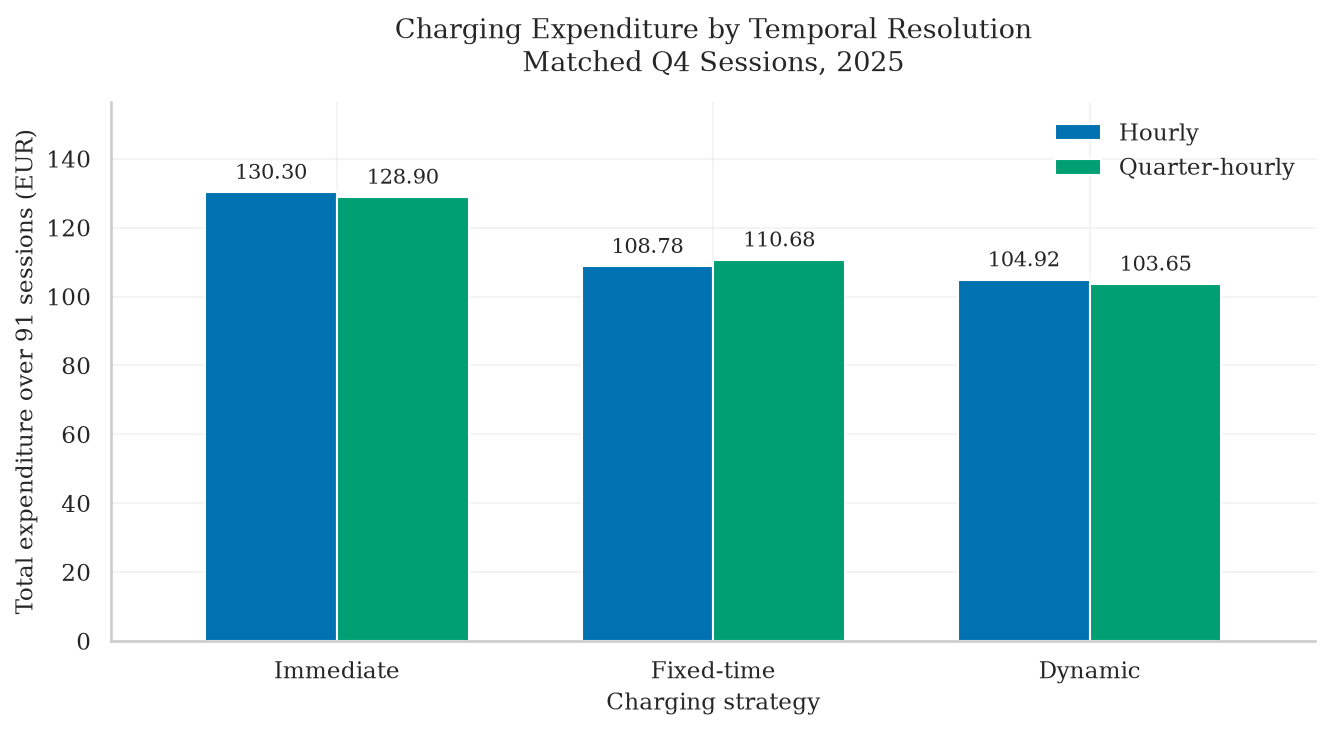

In [85]:
sns.set_theme(
    style="whitegrid",
    palette="colorblind"
)

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.2,
    "pdf.fonttype": 42
})

fig, ax = plt.subplots(figsize=(9, 5))

resolution_costs[
    ["Hourly", "Quarter-hourly"]
].plot(
    kind="bar",
    color=["#0072B2", "#009E73"],
    width=0.7,
    ax=ax
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.2f",
        padding=4,
        fontsize=10
    )

ax.set_title(
    "Charging Expenditure by Temporal Resolution"
    "\nMatched Q4 Sessions, 2025",
    pad=15
)

ax.set_xlabel("Charging strategy")
ax.set_ylabel("Total expenditure over 91 sessions (EUR)")

ax.tick_params(axis="x", rotation=0)

ax.legend(frameon=False)

ax.set_ylim(
    0,
    resolution_costs[
        ["Hourly", "Quarter-hourly"]
    ].to_numpy().max() * 1.20
)

fig.tight_layout()

for extension in ["png", "pdf"]:

    fig.savefig(
        figures_dir
        / f"17_temporal_resolution_robustness.{extension}",
        bbox_inches="tight"
    )

plt.show()

## 9. Validate the main sensitivity findings

In [86]:
# Retrieve independently reconstructed reference costs

immediate_cost = reconstructed_annual.loc[
    "Immediate", "annual_retail_cost_eur"
]

fixed_cost = reconstructed_annual.loc[
    "Fixed-time", "annual_retail_cost_eur"
]

dynamic_cost = reconstructed_annual.loc[
    "Dynamic", "annual_retail_cost_eur"
]

# Confirm reference values
print(f"Immediate cost: EUR {immediate_cost:.4f}")
print(f"Fixed-time cost: EUR {fixed_cost:.4f}")
print(f"Dynamic cost: EUR {dynamic_cost:.4f}")

# Reconstruct duration sensitivity indicators
duration_savings = (
    immediate_cost
    - duration_results["annual_retail_cost_eur"]
)

marginal_values = (
    duration_savings.diff()
    / duration_results.index.to_series().diff()
).dropna()

record_check(
    "V7.1 Duration savings reproduced",
    np.allclose(
        duration_savings,
        duration_results["annual_savings_eur"],
        atol=TOLERANCE,
        rtol=0
    )
)

record_check(
    "V7.2 Diminishing marginal values confirmed",
    (
        marginal_values.diff().dropna()
        <= TOLERANCE
    ).all()
)

# Reconstruct timing advantage
daytime_advantage = (
    timing_results.loc[
        "Overnight", "dynamic_cost_eur"
    ]
    - timing_results.loc[
        "Daytime", "dynamic_cost_eur"
    ]
)

record_check(
    "V7.3 Daytime cost advantage reproduced",
    np.isclose(
        daytime_advantage,
        timing_results.loc[
            "Daytime",
            "cost_advantage_vs_overnight_eur"
        ],
        atol=TOLERANCE,
        rtol=0
    )
)

# Reconstruct tariff invariance
tariff_savings = (
    tariff_results["immediate_cost_eur"]
    - tariff_results["dynamic_cost_eur"]
)

record_check(
    "V7.4 Absolute tariff savings invariant",
    np.allclose(
        tariff_savings,
        immediate_cost - dynamic_cost,
        atol=TOLERANCE,
        rtol=0
    )
)

# Check optimised charging power results
record_check(
    "V7.5 Optimised costs non-increasing with power",
    (
        power_results["dynamic_cost_eur"]
        .sort_index()
        .diff()
        .dropna()
        <= TOLERANCE
    ).all()
)

# Check proportional energy demand savings
savings_per_kwh = (
    energy_results["annual_savings_eur"]
    / energy_results.index
)

record_check(
    "V7.6 Proportional energy demand savings",
    np.allclose(
        savings_per_kwh,
        (immediate_cost - dynamic_cost)
        / ANNUAL_HOME_GRID_ENERGY_KWH,
        atol=TOLERANCE,
        rtol=0
    )
)

# Consolidated economic findings
sensitivity_validation_summary = pd.Series({
    "Savings captured with 8 hours (%)":
        duration_savings.loc[8]
        / duration_savings.loc[12]
        * 100,

    "Additional savings from 10 to 12 hours (EUR)":
        duration_savings.loc[12]
        - duration_savings.loc[10],

    "Daytime advantage (EUR/year)":
        daytime_advantage,

    "Incremental overnight optimisation (EUR/year)":
        fixed_cost - dynamic_cost,

    "Ratio of daytime advantage to optimisation value":
        daytime_advantage / (fixed_cost - dynamic_cost),

    "Maximum timing-related cost difference (EUR)":
        timing_results["dynamic_cost_eur"].max()
        - timing_results["dynamic_cost_eur"].min()

}, name="Value")

display(
    sensitivity_validation_summary.to_frame().round(4)
)

Immediate cost: EUR 513.6141
Fixed-time cost: EUR 457.9247
Dynamic cost: EUR 437.9346
[PASS] V7.1 Duration savings reproduced
[PASS] V7.2 Diminishing marginal values confirmed
[PASS] V7.3 Daytime cost advantage reproduced
[PASS] V7.4 Absolute tariff savings invariant
[PASS] V7.5 Optimised costs non-increasing with power
[PASS] V7.6 Proportional energy demand savings


,Value
Savings captured with 8 hours (%),89.9333
Additional savings from 10 to 12 hours (EUR),1.0906
Daytime advantage (EUR/year),56.4875
Incremental overnight optimisation (EUR/year),19.9900
Ratio of daytime advantage to optimisation value,2.8258
Maximum timing-related cost difference (EUR),59.7271


## 10. Consolidated Validation Report

All structural, mathematical, economic and temporal
validation checks are consolidated into a single report.

The report distinguishes successful computational
validation from unresolved discrepancies.

Passing the validation tests establishes internal
model consistency under the specified assumptions.

It does not establish that the hypothetical charging
profiles accurately represent all EV consumers or
that the simulated economic benefits will persist
under future electricity market conditions.

In [87]:
validation_report = pd.DataFrame(
    validation_records
)

validation_overview = (
    validation_report
    .assign(
        experiment=validation_report[
            "validation_test"
        ].str.extract(r"^(V\d+)")
    )
    .groupby("experiment")
    .agg(
        tests=("passed", "count"),
        passed=("passed", "sum")
    )
)

validation_overview["failed"] = (
    validation_overview["tests"]
    - validation_overview["passed"]
)

display(validation_overview)

total_tests = len(validation_report)

passed_tests = int(
    validation_report["passed"].sum()
)

failed_tests = total_tests - passed_tests

print("=" * 60)
print("FINAL MODEL VALIDATION REPORT")
print("=" * 60)

print("Total validation checks:", total_tests)
print("Passed checks:", passed_tests)
print("Failed checks:", failed_tests)

if failed_tests == 0:

    print("\nAll independent validation checks passed.")

else:

    print("\nUnresolved validation discrepancies:")

    display(
        validation_report.loc[
            ~validation_report["passed"]
        ]
    )


,tests,passed,failed
experiment,,,
V1,10,10,0
V2,2,2,0
V3,6,6,0
V4,3,3,0
V5,13,13,0
V6,7,7,0
V7,6,6,0


FINAL MODEL VALIDATION REPORT
Total validation checks: 47
Passed checks: 47
Failed checks: 0

All independent validation checks passed.


## 11. Export final validation results

In [88]:
# Independent mathematical optimisation
lp_validation.to_csv(
    tables_dir / "independent_lp_validation.csv",
    index=False
)

lp_summary.to_csv(
    tables_dir / "independent_lp_summary.csv",
    header=True
)

# Economic reconstruction
economic_validation.to_csv(
    tables_dir / "economic_reconstruction_validation.csv",
    index=False
)

reconstructed_savings.to_csv(
    tables_dir / "reconstructed_economic_savings.csv",
    header=True
)

# Exceptional conditions
edge_case_results.to_csv(
    tables_dir / "edge_case_validation.csv",
    index=False
)

# Temporal resolution robustness
resolution_session_results.to_csv(
    processed_dir / "temporal_resolution_sessions.csv",
    index=False
)

resolution_costs.to_csv(
    tables_dir / "temporal_resolution_costs.csv"
)

resolution_savings.to_csv(
    tables_dir / "temporal_resolution_savings.csv"
)

# Sensitivity validation
sensitivity_validation_summary.to_csv(
    tables_dir / "sensitivity_validation_summary.csv",
    header=True
)

# Final consolidated report
validation_report.to_csv(
    tables_dir / "final_validation_report.csv",
    index=False
)

validation_overview.to_csv(
    tables_dir / "validation_overview.csv"
)

print("All validation results successfully exported.")

assert validation_report["passed"].all(), (
    "Unresolved validation discrepancies remain."
)

All validation results successfully exported.


In [89]:
outputs = {
    "lp_summary": lp_summary,
    "economic_validation": economic_validation,
    "reconstructed_savings": reconstructed_savings,
    "edge_case_results": edge_case_results,
    "dst_sessions": dst_sessions,
    "resolution_costs": resolution_costs,
    "resolution_savings": resolution_savings,
    "sensitivity_validation_summary":
        sensitivity_validation_summary,
    "validation_overview": validation_overview
}

for name, table in outputs.items():

    print(f"\n{name}")
    print("=" * 70)

    if isinstance(table, pd.Series):
        display(table.to_frame().round(8))
    else:
        display(table.round(8))

print("\nFINAL VALIDATION STATUS")
print("Total checks:", total_tests)
print("Passed:", passed_tests)
print("Failed:", failed_tests)


lp_summary


,Value
Sessions independently optimised,364.000000
Successful LP solutions,364.000000
Matching optimal costs,364.000000
Maximum absolute difference (EUR),0.000000
Total absolute difference (EUR),0.000000
Annualised LP wholesale cost (EUR),121.134648



economic_validation


,strategy,indicator,original,reconstructed,absolute_difference
0,Immediate,annual_energy_kwh,1584.000000,1584.000000,0.0
1,Immediate,annual_spot_cost_eur,196.814111,196.814111,0.0
2,Immediate,annual_retail_cost_eur,513.614111,513.614111,0.0
3,Fixed-time,annual_energy_kwh,1584.000000,1584.000000,0.0
4,Fixed-time,annual_spot_cost_eur,141.124696,141.124696,0.0
5,Fixed-time,annual_retail_cost_eur,457.924696,457.924696,0.0
6,Dynamic,annual_energy_kwh,1584.000000,1584.000000,0.0
7,Dynamic,annual_spot_cost_eur,121.134648,121.134648,0.0
8,Dynamic,annual_retail_cost_eur,437.934648,437.934648,0.0



reconstructed_savings


,Value
Fixed-time annual savings (EUR),55.689415
Dynamic annual savings (EUR),75.679462
Dynamic retail savings (%),14.734693
Incremental dynamic value (EUR),19.990047
Fixed-time share of dynamic savings (%),73.585902


... (9 outputs left out)

,Value
Savings captured with 8 hours (%),89.933263
Additional savings from 10 to 12 hours (EUR),1.090567
Daytime advantage (EUR/year),56.487529
Incremental overnight optimisation (EUR/year),19.990047
Ratio of daytime advantage to optimisation value,2.825783
Maximum timing-related cost difference (EUR),59.727135



validation_overview


,tests,passed,failed
experiment,,,
V1,10,10,0
V2,2,2,0
V3,6,6,0
V4,3,3,0
V5,13,13,0
V6,7,7,0
V7,6,6,0



FINAL VALIDATION STATUS
Total checks: 47
Passed: 47
Failed: 0


## 13. Final Validation and Methodological Interpretation

### 13.1 Computational Validation

All 47 recorded validation checks were successfully completed across seven validation categories.

The original price-ranking charging algorithm was independently benchmarked against the SciPy HiGHS linear programming solver for all 364 reference charging sessions.

The independent solver reproduced the minimum wholesale electricity expenditure within the specified numerical tolerance for every evaluated session.

Furthermore, independently reconstructed electricity quantities and expenditure were consistent with the original simulation results.

The controlled mathematical examples, infeasibility tests, battery constraints and daylight-saving transition checks also produced the expected results.

These findings establish the computational and mathematical consistency of the reference model under its specified assumptions.

### 13.2 Temporal Resolution Robustness

The impact of temporal aggregation was examined using 91 matched overnight charging sessions between October and December 2025.

| Economic indicator | Hourly model (EUR) | Quarter-hourly model (EUR) |
|---|---:|---:|
| Immediate expenditure | 130.30 | 128.90 |
| Fixed-time expenditure | 108.78 | 110.68 |
| Dynamic expenditure | 104.92 | 103.65 |
| Fixed-time savings | 21.52 | 18.22 |
| Dynamic savings | 25.39 | 25.25 |
| Incremental dynamic value | 3.86 | 7.03 |

The aggregate economic ranking of the three charging strategies remains unchanged when using native quarter-hourly electricity prices.

Dynamic charging savings relative to immediate charging decline by approximately 0.54%, indicating limited sensitivity to temporal aggregation during the evaluated period.

However, the incremental economic value of dynamic optimisation relative to fixed-time charging increases by approximately 81.87%.

This difference arises because finer temporal resolution simultaneously increases fixed-time expenditure and reduces dynamically optimised expenditure.

Consequently, hourly aggregation can produce relatively robust estimates of total optimisation savings while understating the incremental value of more sophisticated charging strategies during the evaluated period.

The results must not be extrapolated directly to the entire calendar year because electricity price dynamics differ across seasons.

### 13.3 Verification of Principal Sensitivity Findings

The principal economic indicators obtained in the sensitivity analysis were successfully reconstructed.

Eight hours of daily overnight availability capture 89.93% of the savings available with twelve hours, while extending availability from ten to twelve hours generates only EUR 1.09 in additional annualised savings.

Changing from overnight to daytime availability generates an annualised cost advantage of EUR 56.49, compared with EUR 19.99 in additional savings from dynamic hourly overnight optimisation relative to a midnight charging timer.

These results support the interpretation that the economic value of charging flexibility depends on its quantity, temporal positioning and the sophistication of its optimisation.

The sensitivity validation establishes arithmetic and internal consistency rather than independent solver-based validation of every alternative scenario.

### 13.4 Scope and Limitations of Validation

Successful computational validation does not establish external validity or the representativeness of the hypothetical consumer profiles.

The model retains the following limitations:

- A single electricity market and historical observation year.
- Simplified and constant daily electricity requirements.
- Hypothetical charging availability and mobility patterns.
- Perfect knowledge of relevant electricity prices.
- Illustrative residential tariff structures.
- Exclusion of infrastructure, optimisation service and consumer inconvenience costs.
- Exclusion of grid constraints, emissions optimisation and bidirectional charging.
- Hourly aggregation in the principal annual simulation.

The results should therefore be interpreted as conditional economic estimates of market-driven EV charging flexibility rather than observed household savings or forecasts of future economic benefits.

### 13.5 Final Conclusion

The independent validation supports the computational reliability of the reference charging model and the internal consistency of its principal economic findings.

The temporal-resolution comparison nevertheless demonstrates the importance of critically examining modelling assumptions, particularly when estimating the incremental economic benefits of sophisticated charging technologies.

The computational investigation is considered complete. Its results provide the quantitative foundation for the accompanying academic reflection paper.